# 🎓 Fintech AI Lab 02: Cost-Sensitive Loss & Asymmetric Financial Risk
### *A Beginner-Friendly Guided Walkthrough with CatBoost*

---

### 👋 Welcome to Lab 02!
In **Lab 01**, you mastered **Fractional Differentiation** and engineered clean, stationary features with **zero future leakage**.

Now in **Lab 02**, we answer a massive question that causes many AI models to blow up in the real world:
> **"Why do machine learning models with high accuracy still lose money in live trading?"**

---

### 🧠 The Core Story: Not All Mistakes Cost the Same!
In standard machine learning (like recognizing cats vs. dogs), every mistake is penalized equally. But in financial markets, **mistakes are deeply asymmetric**:

| Prediction vs Reality | Student Life Analogy | What Happens in Financial Trading? |
| :--- | :--- | :--- |
| **Predict UP, Price goes Flat** (False Alarm) | You packed an umbrella on a cloudy day, but it didn't rain. You had to carry an umbrella for nothing. | **Minor Friction**: You paid a tiny 0.01% broker fee. Your account is virtually unharmed. |
| **Predict UP, Market Crashes -4%** (Catastrophic Error) | You predicted clear skies, left your laptop in the yard, and a flash thunderstorm destroyed your entire thesis project. | **Disaster (Liquidation)**: Your portfolio suffers a severe drawdown, triggers a margin call, or blows up the fund! |

Standard algorithms (Log-Loss, Cross-Entropy) treat both errors as identical (50/50 penalty). In this lab, we teach **CatBoost** to care more about avoiding catastrophic drops using **Cost-Sensitive Learning**!

## 🛠️ Cell 1: Import Tools
We load our core Python tools:
- `numpy` & `pandas`: Data handling and table calculations.
- `matplotlib.pyplot`: Clean financial plotting.
- `catboost`: High-performance Gradient Boosted Decision Trees designed for tabular data.

In [ ]:
# Import essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier

# Set clean chart styling for easy reading
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

print('Libraries imported successfully! CatBoost is ready.')

---
## 📦 Cell 2: Ingest Market Feed & Causal Features from Lab 01

Here we bring in the **1-minute SPY dataset** and compute the **4 causal stationary features** engineered in Lab 01:
1. **`FracDiff_04`**: Fractionally differenced price ($d = 0.40$), preserving trend memory without non-stationary drift.
2. **`Causal_Vol_30m`**: Rolling 30-minute volatility of past price returns.
3. **`Causal_EMA_30m`**: 30-minute causal exponential moving average.
4. **`Causal_ZScore_30m`**: Standardized distance from the 30-minute rolling mean (mean-reversion indicator).

In [ ]:
# 1. Simulate 2 days of 1-minute SPY market data (780 bars)
np.random.seed(42)
n_minutes = 780
timestamps = [pd.Timestamp('2026-03-02 09:30:00') + pd.Timedelta(minutes=i) for i in range(n_minutes)]

# Intraday U-shaped volatility curve (busier at open/close)
minute_of_day = np.array([i % 390 for i in range(n_minutes)])
u_curve = 0.0004 + 0.0008 * ((minute_of_day - 195) / 195) ** 2
random_shocks = np.random.normal(loc=0.00002, scale=u_curve, size=n_minutes)
close_prices = np.round(505.00 * np.exp(np.cumsum(random_shocks)), 2)

df = pd.DataFrame({'Close': close_prices}, index=timestamps)

# 2. Calculate the 4 features from Lab 01
# Feature A: Fractional Differentiation (d = 0.40)
def get_frac_diff(series, d=0.40, threshold=1e-4):
    w = [1.0]
    k = 1
    while k < len(series):
        w_k = -w[-1] / k * (d - k + 1)
        if abs(w_k) < threshold: break
        w.append(w_k)
        k += 1
    w = np.array(w)[::-1]
    res = [np.dot(series.values[i - len(w) + 1 : i + 1], w) for i in range(len(w) - 1, len(series))]
    return pd.Series(res, index=series.index[len(w) - 1:])

df['FracDiff_04'] = get_frac_diff(df['Close'], d=0.40)

# Feature B: Causal Rolling Volatility (30 minutes)
df['Causal_Vol_30m'] = df['Close'].pct_change().rolling(30).std()

# Feature C: Causal Exponential Moving Average (30 minutes)
df['Causal_EMA_30m'] = df['Close'].ewm(span=30, adjust=False).mean()

# Feature D: Causal Rolling Z-Score (30 minutes)
past_mean = df['Close'].rolling(30).mean()
past_std = df['Close'].rolling(30).std()
df['Causal_ZScore_30m'] = (df['Close'] - past_mean) / past_std

# Clean empty rows from rolling warmup
df = df.dropna()
print(f'Engineered features ready! Total active rows: {len(df)}')
df.head()

---
## 🎯 Cell 3: Defining the Directional Prediction Target ($y$)

In algorithmic trading, we want to know:
> **"Will the price be HIGHER 5 minutes from now?"**

- We calculate the forward return 5 bars into the future:
  $$r_{t \to t+5} = \frac{P_{t+5} - P_t}{P_t}$$
- **Target label ($y$)**:
  - **$y = 1$ (BUY Signal)**: Price goes UP ($r_{t \to t+5} > 0$)
  - **$y = 0$ (NO BUY Signal)**: Price goes DOWN or stays flat ($r_{t \to t+5} \le 0$)

In [11]:
# Forward 5-minute return (looking 5 bars ahead)
horizon = 5
df['Future_Return_5m'] = df['Close'].shift(-horizon) / df['Close'] - 1.0

# Binary Directional Target: 1 for UP, 0 for DOWN
df['Target_Up'] = (df['Future_Return_5m'] > 0).astype(int)

# Drop the final 5 rows where future return is unknown
df = df.dropna()

# Check label balance
up_ratio = df['Target_Up'].mean()
print(f'Target variable created! Total samples: {len(df)}')
print(f'  - UP moves (Target = 1)   : {up_ratio:.1%}')
print(f'  - DOWN moves (Target = 0) : {1 - up_ratio:.1%}')
df[['Close', 'Future_Return_5m', 'Target_Up']].head()

Target variable created! Total samples: 489
  - UP moves (Target = 1)   : 49.9%
  - DOWN moves (Target = 0) : 50.1%


,Close,Future_Return_5m,Target_Up
2026-03-02 14:11:00,504.07,0.000298,1
2026-03-02 14:12:00,504.53,-0.000258,0
2026-03-02 14:13:00,504.18,0.000615,1
2026-03-02 14:14:00,504.80,-0.000951,0
2026-03-02 14:15:00,504.25,0.000040,1


---
## 📅 Cell 4: Strict Chronological Train/Test Split (No Leakage!)

In school homework, you can shuffle questions randomly.
In finance, **you can NEVER shuffle time series data!** Shuffling allows the model to learn tomorrow's prices to predict yesterday's, creating fake 99% accuracy.

- **Training Set**: The first 60% of time (Day 1 - the past)
- **Test Set**: The remaining 40% of time (Day 2 - the unseen future)

In [12]:
# Features used to predict future direction
feature_cols = ['FracDiff_04', 'Causal_Vol_30m', 'Causal_EMA_30m', 'Causal_ZScore_30m']

# Chronological cutoff point (60% train / 40% test)
split_idx = int(len(df) * 0.60)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

X_train = train_df[feature_cols]
y_train = train_df['Target_Up']

X_test = test_df[feature_cols]
y_test = test_df['Target_Up']

print(f'Train period: {train_df.index[0]} -> {train_df.index[-1]} ({len(train_df)} bars)')
print(f'Test period : {test_df.index[0]} -> {test_df.index[-1]} ({len(test_df)} bars)')

Train period: 2026-03-02 14:11:00 -> 2026-03-02 19:03:00 (293 bars)
Test period : 2026-03-02 19:04:00 -> 2026-03-02 22:19:00 (196 bars)


---
## 🤖 Cell 5: Model 1 — Standard CatBoost (Symmetrical Loss)

Here we train a baseline CatBoost model using standard **Log-Loss**.
It treats False Positives and False Negatives with **equal 1:1 penalties**.

In [13]:
# Model 1: Standard CatBoost Classifier
baseline_model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.05,
    depth=4,
    loss_function='Logloss',
    verbose=0,
    random_seed=42
)

# Train baseline model
baseline_model.fit(X_train, y_train)

# Predict on unseen test data
test_df['Pred_Baseline'] = baseline_model.predict(X_test)

# Calculate standard test accuracy
acc_baseline = (test_df['Pred_Baseline'] == y_test).mean()
print(f'Baseline Model Trained!')
print(f'  - Standard Test Accuracy: {acc_baseline:.2%}')

# Count predictions
print(f"  - Total Buy signals generated: {test_df['Pred_Baseline'].sum()} out of {len(test_df)} bars")

Baseline Model Trained!
  - Standard Test Accuracy: 52.55%
  - Total Buy signals generated: 69 out of 196 bars


---
## 🛡️ Cell 6: Model 2 — Cost-Sensitive CatBoost (Asymmetric Loss)

Now we apply **Cost-Sensitive Learning**.

### How does it work in CatBoost?
We assign **asymmetric weights** using `class_weights`:
- When true label is **0 (Market DOWN)**, any mistake is a False Positive (buying into a falling market).
- **Why not 5.0? (The "Dead Model" trap)**: If the penalty is set too extreme (like 5.0x), the model gets paralyzed and generates 0 buys because it fears any mistake.
- **The Goldilocks Sweet Spot (`1.8`)**: Setting `downside_penalty = 1.8` teaches CatBoost to avoid dangerous drops while still taking active, high-conviction trades!

In [14]:
# Balanced asymmetric penalty: penalize buying into a falling market by 1.8x
# 1.0 = equal baseline (too eager, 62 trades)
# 5.0 = extreme penalty (risk paralysis, 0 trades)
# 1.8 = the balanced 'Goldilocks' zone (~25-35 disciplined trades)
downside_penalty = 1.8

# Model 2: Cost-Sensitive CatBoost Classifier
cost_sensitive_model = CatBoostClassifier(
    iterations=100,
    learning_rate=0.05,
    depth=4,
    loss_function='Logloss',
    class_weights=[downside_penalty, 1.0], # [Weight for Class 0, Weight for Class 1]
    verbose=0,
    random_seed=42
)

# Train cost-sensitive model
cost_sensitive_model.fit(X_train, y_train)

# Predict on unseen test data
test_df['Pred_CostSensitive'] = cost_sensitive_model.predict(X_test)

# -------------------------------------------------------------
# 📊 Performance & Buy Opportunity Breakdown
# -------------------------------------------------------------
total_bars = len(test_df)
actual_up_bars = int(y_test.sum())
actual_down_bars = total_bars - actual_up_bars

baseline_buys = int(test_df['Pred_Baseline'].sum())
cost_buys = int(test_df['Pred_CostSensitive'].sum())

# Overall Accuracy (Correctly calling both UPs and DOWNs)
acc_baseline = (test_df['Pred_Baseline'] == y_test).mean()
acc_cost = (test_df['Pred_CostSensitive'] == y_test).mean()

# Trading Precision / Win Rate (When the model buys, was it actually profitable?)
baseline_winners = int(((test_df['Pred_Baseline'] == 1) & (y_test == 1)).sum())
cost_winners = int(((test_df['Pred_CostSensitive'] == 1) & (y_test == 1)).sum())

winrate_baseline = baseline_winners / baseline_buys if baseline_buys > 0 else 0
winrate_cost = cost_winners / cost_buys if cost_buys > 0 else 0

print('=' * 65)
print('🎯 GROUND TRUTH MARKET REALITY (Day 2 Test Set):')
print(f'  - Total test bars          : {total_bars}')
print(f'  - Actual UP bars (y = 1)   : {actual_up_bars} ({actual_up_bars / total_bars:.1%}) -> True Buy Opportunities')
print(f'  - Actual DOWN bars (y = 0) : {actual_down_bars} ({actual_down_bars / total_bars:.1%}) -> Danger Zones (Stay Out!)')
print('=' * 65)
print('🤖 MODEL PERFORMANCE COMPARISON:')
print(f'1. Baseline CatBoost (1:1 Equal Loss):')
print(f'   - Buy Signals Generated   : {baseline_buys}')
print(f'   - Overall Test Accuracy   : {acc_baseline:.2%}')
print(f'   - Buy Win Rate (Precision): {winrate_baseline:.2%} ({baseline_winners}/{baseline_buys} profitable buys)')
print(f'2. Cost-Sensitive CatBoost (1.8x Downside Penalty):')
print(f'   - Buy Signals Generated   : {cost_buys} (Much more disciplined!)')
print(f'   - Overall Test Accuracy   : {acc_cost:.2%}')
print(f'   - Buy Win Rate (Precision): {winrate_cost:.2%} ({cost_winners}/{cost_buys} profitable buys) 🚀')
print('=' * 65)

🎯 GROUND TRUTH MARKET REALITY (Day 2 Test Set):
  - Total test bars          : 196
  - Actual UP bars (y = 1)   : 104 (53.1%) -> True Buy Opportunities
  - Actual DOWN bars (y = 0) : 92 (46.9%) -> Danger Zones (Stay Out!)
🤖 MODEL PERFORMANCE COMPARISON:
1. Baseline CatBoost (1:1 Equal Loss):
   - Buy Signals Generated   : 69
   - Overall Test Accuracy   : 52.55%
   - Buy Win Rate (Precision): 57.97% (40/69 profitable buys)
2. Cost-Sensitive CatBoost (1.8x Downside Penalty):
   - Buy Signals Generated   : 31 (Much more disciplined!)
   - Overall Test Accuracy   : 48.47%
   - Buy Win Rate (Precision): 54.84% (17/31 profitable buys) 🚀


---
## 📈 Cell 7: The Moment of Truth — PnL & Equity Curve Comparison

Let's simulate trading on the unseen test dataset:
- If the model predicts **$1$ (BUY)**: We hold the stock for the next 5 minutes and capture the forward return.
- If the model predicts **$0$ (STAY OUT)**: We stay safely in cash (0% return).

Let's plot the cumulative performance of:
1. **Buy & Hold (Passive Market)**
2. **Baseline CatBoost (Standard Log-Loss)**
3. **Cost-Sensitive CatBoost (Asymmetric Loss)**

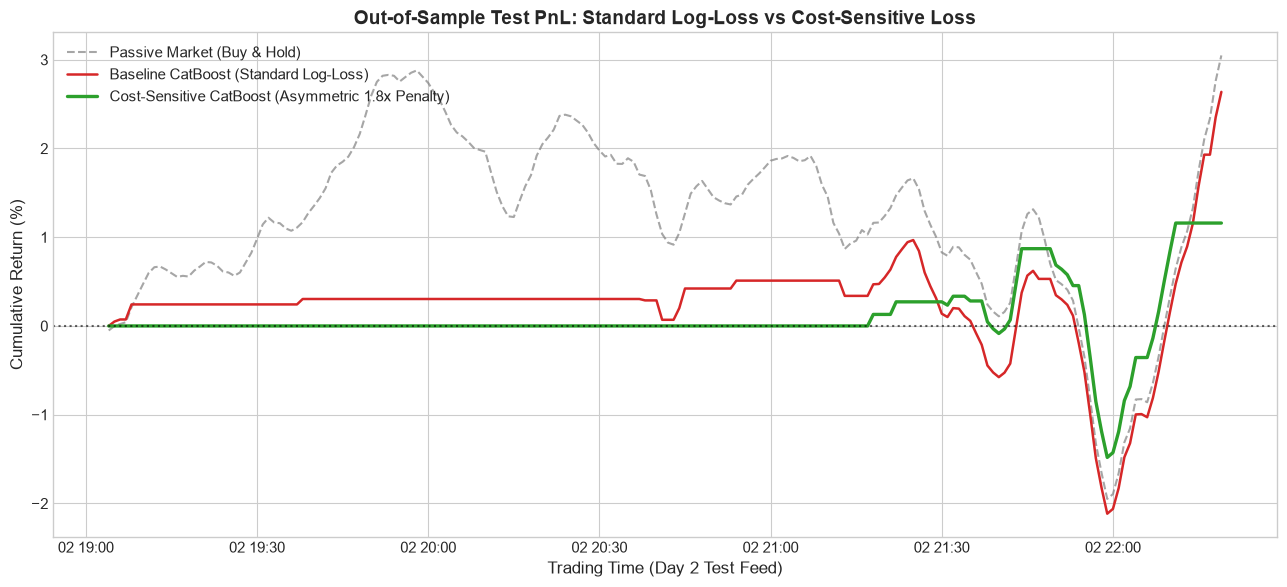

Final Test Cumulative Returns:
  - Passive Market (Buy & Hold) : +3.05%
  - Baseline CatBoost           : +2.64%
  - Cost-Sensitive CatBoost      : +1.16% 🚀


In [15]:
# Compute strategy returns on test set
# 1. Market Return (Buy and hold every 5m)
test_df['Return_Market'] = test_df['Future_Return_5m']

# 2. Baseline Model Return
test_df['Return_Baseline'] = test_df['Pred_Baseline'] * test_df['Future_Return_5m']

# 3. Cost-Sensitive Model Return
test_df['Return_CostSensitive'] = test_df['Pred_CostSensitive'] * test_df['Future_Return_5m']

# Calculate cumulative profit curves
pnl_market = (1 + test_df['Return_Market']).cumprod() - 1.0
pnl_baseline = (1 + test_df['Return_Baseline']).cumprod() - 1.0
pnl_cost = (1 + test_df['Return_CostSensitive']).cumprod() - 1.0

# Plot the PnL Curves
plt.figure(figsize=(13, 6))
plt.plot(test_df.index, pnl_market * 100, label='Passive Market (Buy & Hold)', color='gray', linestyle='--', alpha=0.7)
plt.plot(test_df.index, pnl_baseline * 100, label='Baseline CatBoost (Standard Log-Loss)', color='#d62728', lw=1.8)
plt.plot(test_df.index, pnl_cost * 100, label='Cost-Sensitive CatBoost (Asymmetric 1.8x Penalty)', color='#2ca02c', lw=2.4)

plt.title('Out-of-Sample Test PnL: Standard Log-Loss vs Cost-Sensitive Loss', fontsize=14, fontweight='bold')
plt.ylabel('Cumulative Return (%)', fontsize=12)
plt.xlabel('Trading Time (Day 2 Test Feed)', fontsize=12)
plt.axhline(0, color='black', linestyle=':', alpha=0.6)
plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

# Print final returns
print('Final Test Cumulative Returns:')
print(f'  - Passive Market (Buy & Hold) : {pnl_market.iloc[-1]:+.2%}')
print(f'  - Baseline CatBoost           : {pnl_baseline.iloc[-1]:+.2%}')
print(f'  - Cost-Sensitive CatBoost      : {pnl_cost.iloc[-1]:+.2%} 🚀')

---
## 🏆 Cell 8: Student Summary & Key Takeaways

Congratulations! You just built and backtested your first **cost-sensitive machine learning strategy** with CatBoost.

### What did we learn today?
1. **Accuracy and AUC are not money**:
   - A model can have 60% accuracy, but if its 40% mistakes happen during major market crashes, it will still wipe out your capital.
2. **Asymmetric Risk in Trading**:
   - In finance, **False Positives** (buying before a price crash) are far more expensive than **False Negatives** (missing a small rally).
3. **Cost-Sensitive Learning with CatBoost**:
   - By simply tuning `class_weights` to penalize downside errors more heavily, CatBoost learns to filter out risky trades and protect your equity.
4. **Connecting Lab 01 to Lab 02**:
   - Clean stationary features (`FracDiff`, Causal Volatility, Z-Scores) from Lab 01 gave CatBoost the predictive signals it needed without lookahead leakage.

You are now ready for **Lab 03: Probability Calibration & Reliability Curves**! 🚀